<a href="https://colab.research.google.com/github/MANDEEP9711/scikit_learning/blob/main/pipelinesipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install ucimlrepo


  Using cached ucimlrepo-0.0.7-py3-none-any.whl.metadata (5.5 kB)
Using cached ucimlrepo-0.0.7-py3-none-any.whl (8.0 kB)
Note: you may need to restart the kernel to use updated packages.


In [93]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
bank_marketing = fetch_ucirepo(id=222) 
  
# data (as pandas dataframes) 
X = bank_marketing.data.features 
y = bank_marketing.data.targets 
X.info()


<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          45211 non-null  int64
 1   job          44923 non-null  str  
 2   marital      45211 non-null  str  
 3   education    43354 non-null  str  
 4   default      45211 non-null  str  
 5   balance      45211 non-null  int64
 6   housing      45211 non-null  str  
 7   loan         45211 non-null  str  
 8   contact      32191 non-null  str  
 9   day_of_week  45211 non-null  int64
 10  month        45211 non-null  str  
 11  duration     45211 non-null  int64
 12  campaign     45211 non-null  int64
 13  pdays        45211 non-null  int64
 14  previous     45211 non-null  int64
 15  poutcome     8252 non-null   str  
dtypes: int64(7), str(9)
memory usage: 5.5 MB


In [99]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


(array([3.6954e+04, 1.4070e+03, 2.8790e+03, 1.4740e+03, 2.2630e+03,
        1.2700e+02, 5.5000e+01, 1.9000e+01, 2.2000e+01, 1.1000e+01]),
 array([ -1.,   0., 100., 200., 300., 400., 500., 600., 700., 800., 900.]),
 <BarContainer object of 10 artists>)

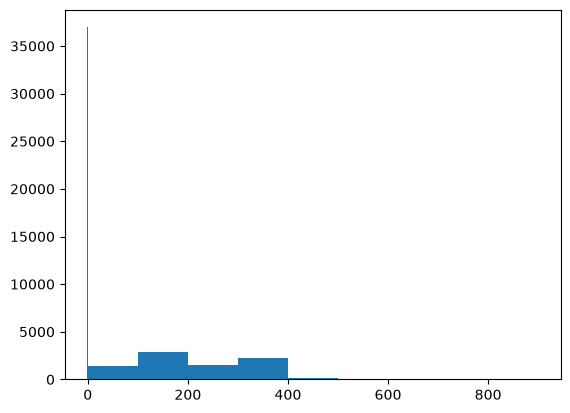

In [98]:
X["pdays"].unique()
bins = [-1,0,100,200,300,400,500,600,700,800,900]

plt.hist(X["pdays"], bins, histtype='bar')

In [ ]:
tot=X[X["pdays"]<301]
print(tot.shape)

<class 'pandas.Series'>
Index: 42741 entries, 0 to 45210
Series name: pdays
Non-Null Count  Dtype
--------------  -----
42741 non-null  int64
dtypes: int64(1)
memory usage: 667.8 KB
(42741, 15)


In [54]:
X['previously_contacted'] = (X['pdays'] != -1).astype(int)

<Axes: >

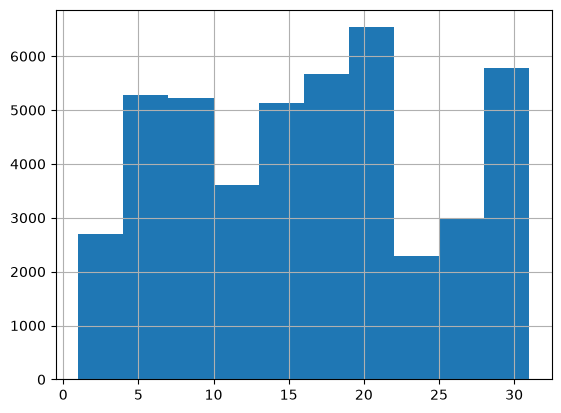

In [77]:
X["day_of_week"].hist()

In [73]:
X.describe(include="str")
col=X.select_dtypes(include=['str'])
l=[X[cols].unique() for cols in col.columns]
l


[<StringArray>
 [   'management',    'technician',  'entrepreneur',   'blue-collar',
              nan,       'retired',        'admin.',      'services',
  'self-employed',    'unemployed',     'housemaid',       'student']
 Length: 12, dtype: str,
 <StringArray>
 ['married', 'single', 'divorced']
 Length: 3, dtype: str,
 <StringArray>
 ['tertiary', 'secondary', nan, 'primary']
 Length: 4, dtype: str,
 <StringArray>
 ['no', 'yes']
 Length: 2, dtype: str,
 <StringArray>
 ['yes', 'no']
 Length: 2, dtype: str,
 <StringArray>
 ['no', 'yes']
 Length: 2, dtype: str,
 <StringArray>
 ['Missing contact no', 'cellular', 'telephone']
 Length: 3, dtype: str,
 <StringArray>
 ['may', 'jun', 'jul', 'aug', 'oct', 'nov', 'dec', 'jan', 'feb', 'mar', 'apr',
  'sep']
 Length: 12, dtype: str]

In [55]:
X.describe()

,age,balance,day_of_week,duration,campaign,pdays,previous,previously_contacted
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323,0.182633
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441,0.386369
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000,1.000000


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer


In [ ]:
X.drop(columns=["poutcome"],inplace=True)
X["contact"]=X["contact"].fillna("Missing contact no")
X["education"]=X["education"].fillna(X["education"].mode()[0])

In [96]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import train_test_split

# Drop poutcome
#X = X.drop(columns=['poutcome'])

# Define imputers
contact_imputer = SimpleImputer(
    strategy='constant',
    fill_value='Missing contact no'
)

education_imputer = SimpleImputer(
    strategy='most_frequent'
)

# Apply preprocessing to selected columns
preprocessor = ColumnTransformer(
    transformers=[
        ('contact', contact_imputer, ['contact']),
        ('education', education_imputer, ['education','job'])
    ],
    remainder='passthrough',
    verbose_feature_names_out=False
).set_output(transform='pandas')

# Create pipeline
pipe = Pipeline([
    ('preprocessor', preprocessor)
])

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=2)
print(f"X_train size: {X_train.shape}")
print(f"X_train size: {X_test.shape}")
print(f"X_train size: {y_train.shape}")
print(f"X_train size: {y_test.shape}")
# Fit on training data only
X_train = pipe.fit_transform(X_train)
X_test = pipe.transform(X_test)

X_train size: (36168, 15)
X_train size: (9043, 15)
X_train size: (36168, 1)
X_train size: (9043, 1)


In [97]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 36168 entries, 27534 to 23720
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   contact      36168 non-null  str  
 1   education    36168 non-null  str  
 2   job          36168 non-null  str  
 3   age          36168 non-null  int64
 4   marital      36168 non-null  str  
 5   default      36168 non-null  str  
 6   balance      36168 non-null  int64
 7   housing      36168 non-null  str  
 8   loan         36168 non-null  str  
 9   day_of_week  36168 non-null  int64
 10  month        36168 non-null  str  
 11  duration     36168 non-null  int64
 12  campaign     36168 non-null  int64
 13  pdays        36168 non-null  int64
 14  previous     36168 non-null  int64
dtypes: int64(7), str(8)
memory usage: 4.4 MB
